In [ ]:
# %%
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [ ]:
# %%
rate = pd.read_csv('data/err_collision_rate.csv')
collision_labels = ['Partial Sum HW', 'Partial Sum HD', 'Partial Sum Value', 'Multipication Value']
# collision rate per weight index, averaged over all layers
collision_series = [rate[rate.series == s].sort_values('weight_index')['collision_rate'].to_numpy() for s in collision_labels]

In [ ]:
def plot_index_probabilities_scatter(
    probs_list,
    labels,
    title="Mismatch Probability per Index",
    xlabel="Index",
    ylabel="Probability",
    markers=None,
    linestyles=None,
    figsize=(10, 5),
    fontsize=12,
    legend_outside=False,
    legend_loc="upper left"
):
    """
    Plot scatter + line of probabilities per index for multiple series.

    Adds:
      - unique markers per series (by default)
      - legend placement that avoids hiding data (outside by default)
    """
    n_series = len(probs_list)
    if len(labels) != n_series:
        raise ValueError("`labels` must match number of series in `probs_list`")

    # ---- Default unique marker shapes (cycle if needed) ----
    default_markers = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "H", "p", "8", "+"]
    if markers is None:
        markers = [default_markers[i % len(default_markers)] for i in range(n_series)]
    elif len(markers) < n_series:
        # extend user-provided markers by cycling
        markers = [markers[i % len(markers)] for i in range(n_series)]

    # ---- Optional: also make line styles unique (nice when many lines overlap) ----
    default_linestyles = ["-", "--", "-.", ":"]
    if linestyles is None:
        linestyles = [default_linestyles[i % len(default_linestyles)] for i in range(n_series)]
    elif len(linestyles) < n_series:
        linestyles = [linestyles[i % len(linestyles)] for i in range(n_series)]

    fig, ax = plt.subplots(figsize=figsize)

    for probs, label, m, ls in zip(probs_list, labels, markers, linestyles):
        probs = np.asarray(probs)
        indices = np.arange(probs.shape[0])

        ax.scatter(indices, probs, marker=m, label=label, s=200)
        ax.plot(indices, probs, linestyle=ls, alpha=0.7)

    ax.set_title(title, fontsize=fontsize)
    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)

    ax.set_xscale("symlog")
    ax.tick_params(axis="both", labelsize=fontsize)

    ax.set_ylim(0, 1)
    ax.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.7)

    # ---- Legend placement that doesn't hide information ----
    if legend_outside:
        # Put legend outside on the right
            leg = ax.legend(
            fontsize=fontsize-3,
            loc="center left",
            bbox_to_anchor=(20, 0.62),      # (x, y) in *data* units
            bbox_transform=ax.transData,    # interpret bbox_to_anchor as data coords
            framealpha=0.95
        )
    else:
        ax.legend(fontsize=fontsize-7, loc="best")
        fig.tight_layout()

    plt.savefig(
        "../plots/collision_rate.pdf",
        format="pdf",
        bbox_inches="tight",
        metadata={"Creator": "Matplotlib"},
    )
    plt.show()

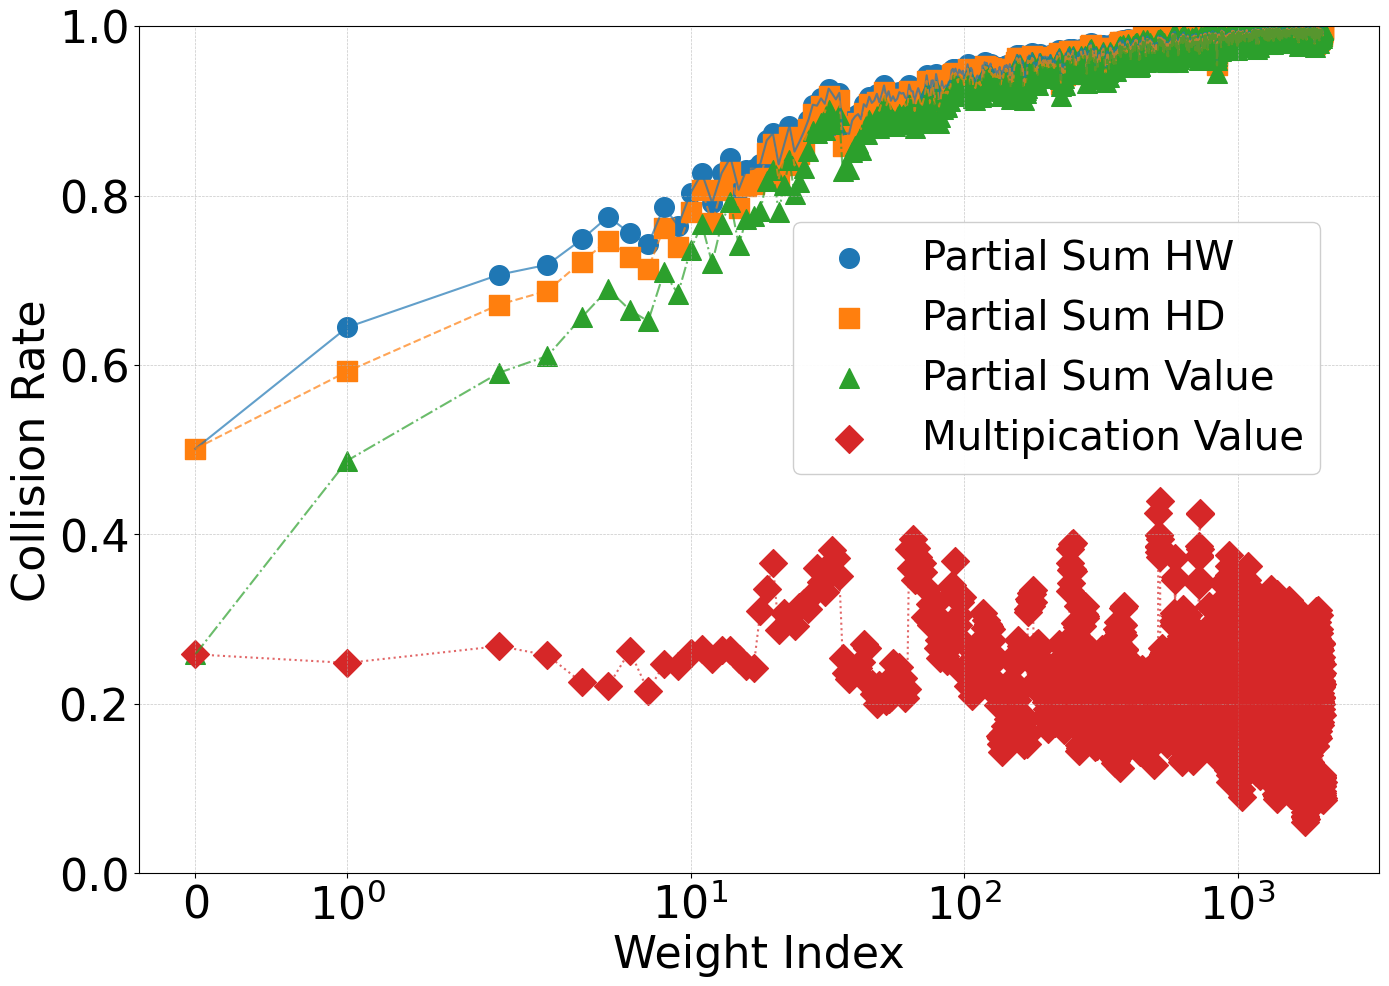

In [ ]:
plot_index_probabilities_scatter(
    collision_series,
    title="",
    xlabel="Weight Index",
    ylabel="Collision Rate",
    labels=collision_labels,
    fontsize=32,
    figsize=(16, 11), 
    legend_outside = True
)

Mantissa Histogram

In [ ]:
mant = pd.read_csv('data/err_collision_mantissa.csv').sort_values('mantissa')
coll_by_mant = mant['collisions'].to_numpy()
total_by_mant = mant['total'].to_numpy()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_collision_prob_by_mantissa_bins(
    coll_by_mant,
    total_by_mant,
    bin_width=5,
    mant_max=1023,
    figsize=(22, 8),
    font_size=24,
    title="",
    xlabel=None,
    ylabel="Collision Rate",
    msb_boundary=512,
    x_tick_step=64,
    x_rotation=45,
    show=True,
    save_dir="../plots",
    filename="collision_prob_by_mantissa_bins.pdf"
):
    """
    Weighted binning:
      prob_bin = (sum collisions in bin) / (sum totals in bin)

    coll_by_mant / total_by_mant are arrays indexed by mantissa value (0..mant_max).
    No font family is set (avoids findfont warnings).
    """
    coll_by_mant = np.asarray(coll_by_mant)
    total_by_mant = np.asarray(total_by_mant)

    if coll_by_mant.shape != total_by_mant.shape:
        raise ValueError("coll_by_mant and total_by_mant must have the same shape")
    if mant_max >= coll_by_mant.shape[0]:
        raise ValueError(f"mant_max={mant_max} is out of range for arrays of length {coll_by_mant.shape[0]}")
    if xlabel is None:
        xlabel = f"Mantissa value"

    # Slice to 0..mant_max inclusive
    coll = coll_by_mant[:mant_max + 1]
    total = total_by_mant[:mant_max + 1]

    # Build bins
    edges = np.arange(0, mant_max + 1 + bin_width, bin_width)
    centers = (edges[:-1] + edges[1:]) / 2

    # Weighted binning
    coll_bin = np.add.reduceat(coll, edges[:-1])
    total_bin = np.add.reduceat(total, edges[:-1])
    prob_bin = np.divide(
        coll_bin, total_bin,
        out=np.zeros_like(coll_bin, dtype=float),
        where=total_bin > 0
    )

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(centers, prob_bin, width=bin_width, align="center",
           edgecolor="black", linewidth=0.4)

    ax.set_xlim(0, mant_max)
    ymax = float(np.nanmax(prob_bin)) if prob_bin.size else 1.0
    ax.set_ylim(0, min(1.0, ymax * 1.05 if ymax > 0 else 1.0))

    ax.set_xlabel(xlabel, fontsize=font_size)
    ax.set_ylabel(ylabel, fontsize=font_size)
    ax.set_title(title, fontsize=font_size)

    if msb_boundary is not None:
        ax.axvline(msb_boundary, linestyle="--", linewidth=1.5)

    ax.grid(True, which="both", axis="y", linestyle="--", linewidth=0.7, alpha=0.6)

    # X ticks + rotation
    if x_tick_step is not None and x_tick_step > 0:
        xticks = np.arange(0, mant_max + 1, x_tick_step)
        ax.set_xticks(xticks)

    ax.tick_params(axis="both", labelsize=font_size)
    ax.tick_params(axis="x", labelrotation=x_rotation)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right" if x_rotation else "center")

    fig.tight_layout()

    # Save
    save_path = f"{save_dir.rstrip('/')}/{filename}"
    fig.savefig(save_path, format=filename.split(".")[-1], bbox_inches="tight",
                metadata={"Creator": "Matplotlib"})

    if show:
        plt.show()

    return fig, ax, prob_bin, centers

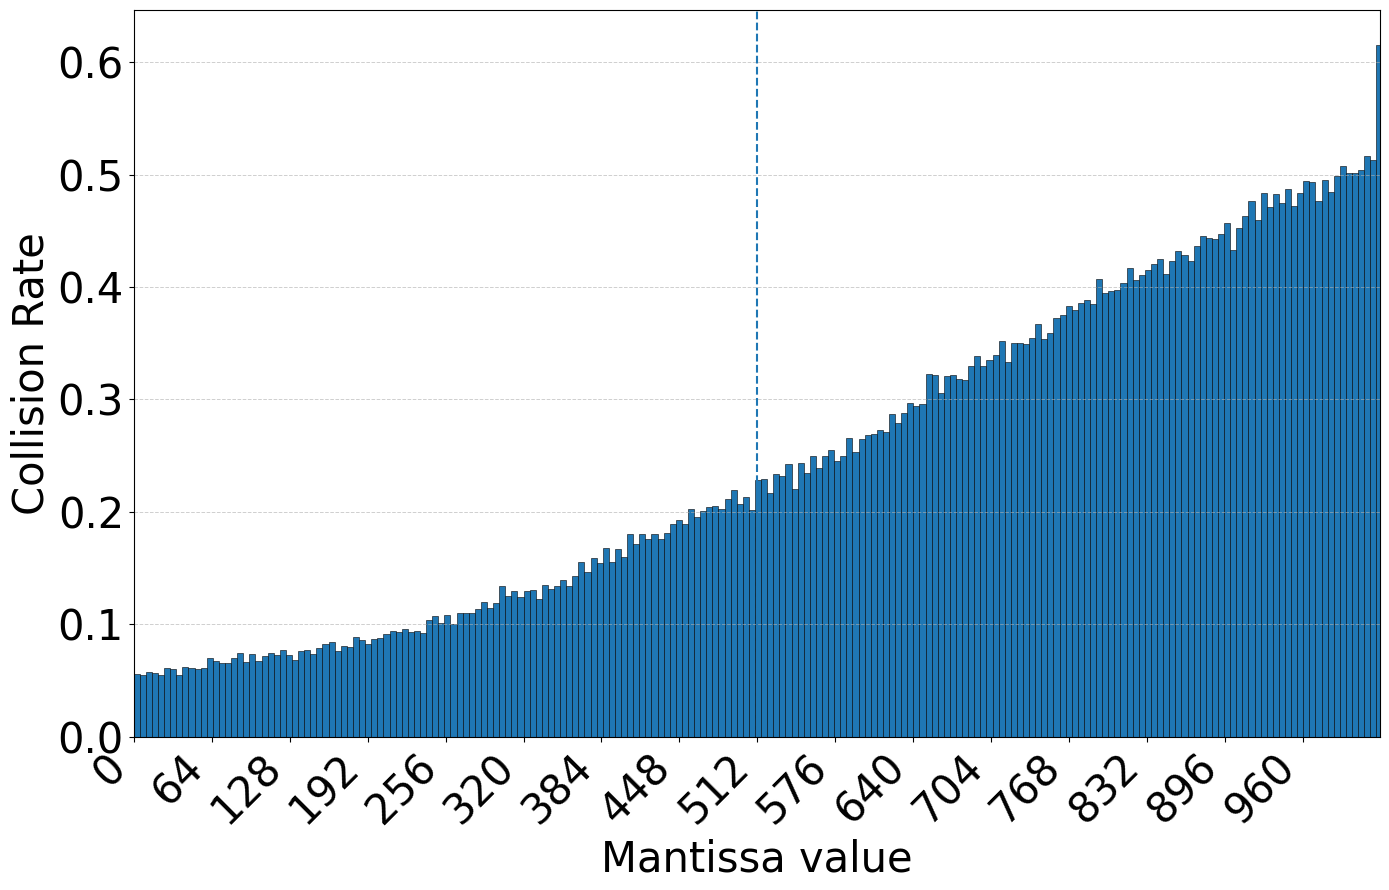

In [ ]:
fig, ax, prob_bin, centers = plot_collision_prob_by_mantissa_bins(
    coll_by_mant, total_by_mant,
    bin_width=5,
    font_size=30,
    figsize=(14, 9),
    filename="multi_collision_prob_mantissa.pdf"
)

Exponent Diff Histogram

In [ ]:
delta = pd.read_csv('data/err_collision_delta_exp.csv')

def delta_hist(eps_sign):
    d = delta[delta.eps_sign == eps_sign].sort_values('exp_diff')
    return d['exp_diff'].to_numpy(), d['prob_collision'].to_numpy(), d['prob_no_collision'].to_numpy()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib as mpl

mpl.rcParams["hatch.linewidth"] = 4.5  # make hatches visible when scaled in Overleaf

def plot_delta_exp_histogram_hatched(
    xs,
    prob_equiv,
    prob_unequiv,
    figsize=(12, 8),
    font_size=28,
    bar_w=0.72,                  # wider bars
    legend_loc=("center left", (0.02, 0.55)),
    hatch_equiv="////",
    hatch_unequiv="xx",
    alpha=0.95,
    savepath=None,
    x_rotation=0
):
    xs = np.asarray(xs)
    prob_equiv = np.asarray(prob_equiv, dtype=float)
    prob_unequiv = np.asarray(prob_unequiv, dtype=float)

    fig, ax = plt.subplots(figsize=figsize)

    # --- Base bars (Matplotlib chooses the SAME default colors as your original) ---
    bars1 = ax.bar(
        xs - bar_w/2, prob_equiv, width=bar_w,
        label="collision", edgecolor="black", linewidth=0.8, alpha=alpha, zorder=2
    )
    bars2 = ax.bar(
        xs + bar_w/2, prob_unequiv, width=bar_w,
        label="no-collision", edgecolor="black", linewidth=0.8, alpha=alpha, zorder=2
    )

    # Grab the EXACT colors Matplotlib used (for legend + consistency)
    c1 = bars1[0].get_facecolor()
    c2 = bars2[0].get_facecolor()

    # --- Hatch overlay (black hatch on top of the SAME colored bars) ---
    ax.bar(xs - bar_w/2, prob_equiv, width=bar_w,
           facecolor="none", edgecolor="black", linewidth=0.0,
           hatch=hatch_equiv, zorder=3)
    ax.bar(xs + bar_w/2, prob_unequiv, width=bar_w,
           facecolor="none", edgecolor="black", linewidth=0.0,
           hatch=hatch_unequiv, zorder=3)

    ax.set_xlabel("Exponent difference", fontsize=font_size)
    ax.set_ylabel("Probability", fontsize=font_size)
    ax.tick_params(axis="both", labelsize=font_size)
    ax.tick_params(axis="x", labelrotation=x_rotation)

    ax.grid(True, axis="y", linestyle="--", linewidth=0.7, alpha=0.6, zorder=1)

    # Legend that shows the SAME colors + the hatches clearly
    handles = [
        Patch(facecolor=c1, edgecolor="black", hatch=hatch_equiv, label="collision"),
        Patch(facecolor=c2, edgecolor="black", hatch=hatch_unequiv, label="no-collision"),
    ]
    loc, anchor = legend_loc
    ax.legend(handles=handles, fontsize=font_size, loc=loc, bbox_to_anchor=anchor, framealpha=0.95)

    fig.tight_layout()

    if savepath is not None:
        # Best for Overleaf: vector PDF
        if savepath.lower().endswith(".png"):
            fig.savefig(savepath, dpi=900, bbox_inches="tight", metadata={"Creator": "Matplotlib"})
        else:
            if not savepath.lower().endswith(".pdf"):
                savepath += ".pdf"
            fig.savefig(savepath, bbox_inches="tight", metadata={"Creator": "Matplotlib"})

    plt.show()
    return fig, ax

In [ ]:
xs_pls, prob_eq_pls, prob_uneq_pls = delta_hist('plus')

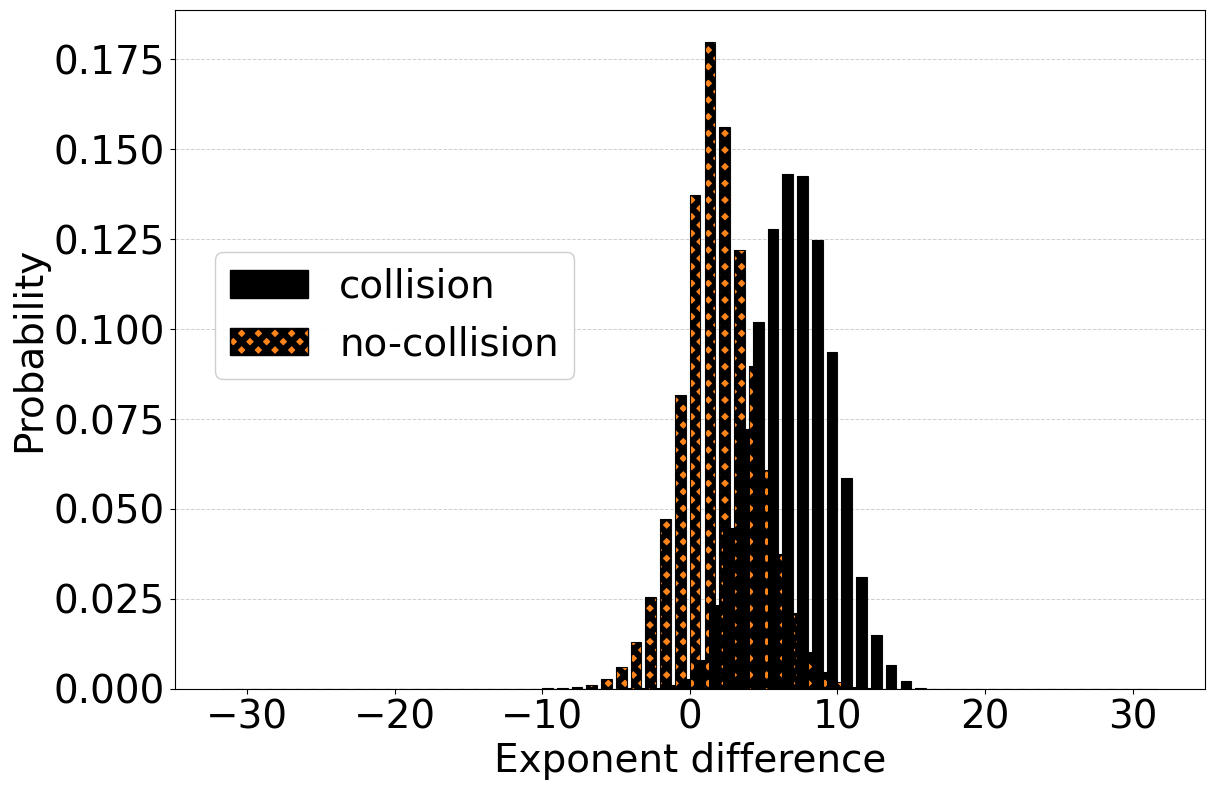

(<Figure size 1200x800 with 1 Axes>,
 <Axes: xlabel='Exponent difference', ylabel='Probability'>)

In [ ]:
plot_delta_exp_histogram_hatched(
    xs_pls, prob_eq_pls, prob_uneq_pls,
    savepath="../plots/delta_exp_hist_plus_eps.pdf",
    legend_loc=("center left", (0.02, 0.55)),
    x_rotation=0
)

In [ ]:
xs_minus, prob_eq_minus, prob_uneq_minus = delta_hist('minus')

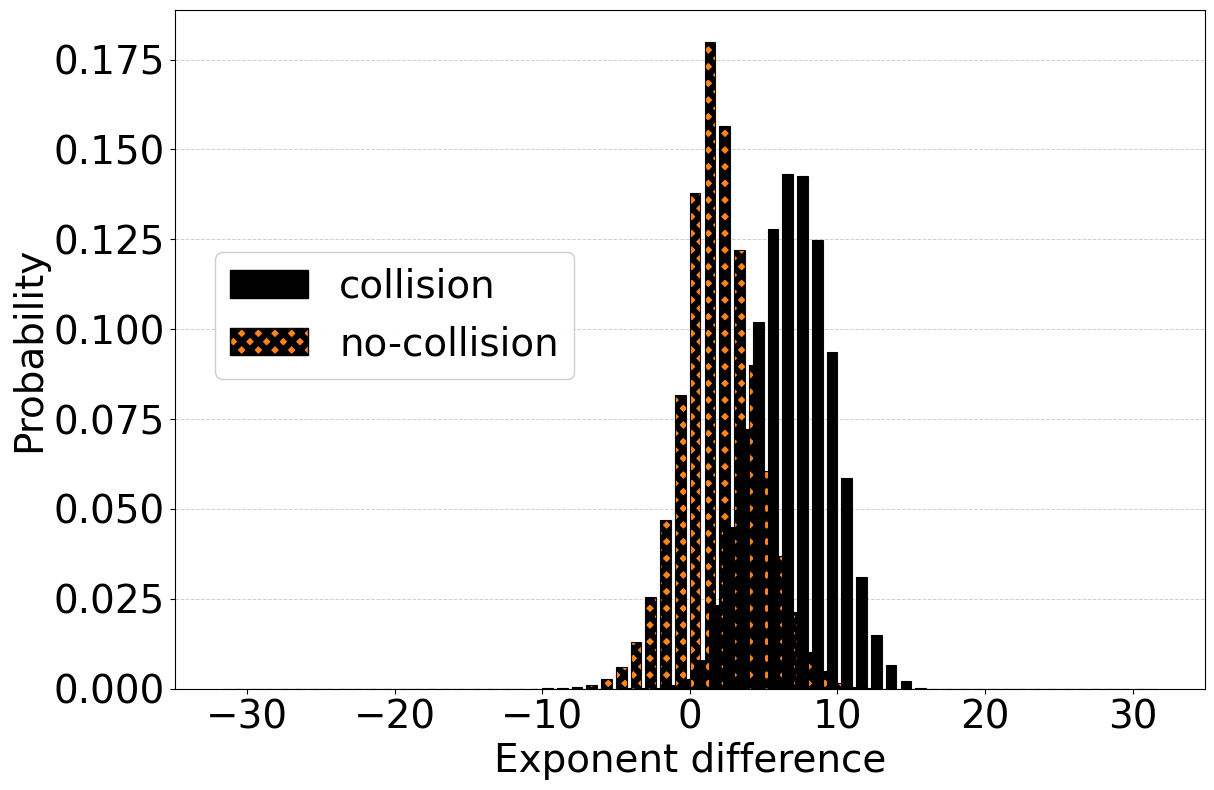

(<Figure size 1200x800 with 1 Axes>,
 <Axes: xlabel='Exponent difference', ylabel='Probability'>)

In [ ]:
plot_delta_exp_histogram_hatched(
    xs_minus, prob_eq_minus, prob_uneq_minus,
    savepath="../plots/delta_exp_hist_minus_eps.pdf",
    legend_loc=("center left", (0.02, 0.55)),
    x_rotation=0
)

Previous Sum Distribution

In [ ]:
ps = pd.read_csv('data/err_collision_prev_sum.csv')

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def seaborn_boxplot_symlog_colored(
    arr,
    bins=None,
    num_bins=30,
    figsize=(14,6), fontsize=12,
    showfliers=True
):
    F, W = arr.shape

    # --- choose log-binned indices (and keep 0) ---
    if bins is None:
        idxs = np.unique(np.rint(np.geomspace(1, W-1, num_bins)).astype(int))
        idxs = np.insert(idxs, 0, 0)
    else:
        idxs = np.array(sorted(set(bins)))
        idxs = idxs[idxs < W]

    # long-form dataframe for seaborn
    df = pd.DataFrame(arr[:, idxs])
    df = df.melt(var_name="col_idx", value_name="Value")

    # map melt column indices back to actual weight indices
    real_idxs = dict(zip(range(len(idxs)), idxs))
    df["WeightIndexNum"] = df["col_idx"].map(real_idxs)

    # make x categorical with the exact desired order
    cats = [str(i) for i in idxs]
    df["WeightIndex"] = pd.Categorical(df["WeightIndexNum"].astype(str),
                                       categories=cats, ordered=True)

    # color per box (optional)
    df["bin_id"] = df["WeightIndex"]

    plt.figure(figsize=figsize)
    ax = sns.boxplot(
        data=df,
        x="WeightIndex", y="Value",
        hue="bin_id", dodge=False,
        showfliers=showfliers,
        linewidth=1.2
    )

    # --- axis & labels ---
    ax.set_xlabel("Weight Index", fontsize=fontsize)
    ax.set_ylabel("Partial Sum Distribution", fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.grid(True, which="both", alpha=0.3)

    # show only every Nth x label
    N = max(int(2), 1)
    ticks = np.arange(2, len(cats), N)
    ax.set_xticks(ticks)
    ax.set_xticklabels([cats[i] for i in ticks], rotation=45, ha="center", fontsize=fontsize)

    # optional: trim huge legend
    if ax.get_legend() is not None:
        ax.legend_.set_title("Weight Index", prop={'size': fontsize})
        for text in ax.legend_.get_texts():
            text.set_fontsize(fontsize)

    plt.tight_layout()
    plt.savefig("../plots/prev_sum_growth.pdf",
            format="pdf",
            bbox_inches="tight",
            metadata={"Creator": "Matplotlib"})
    plt.show()

In [ ]:
# mean |partial sum| over inputs, per (fc1 filter, weight index); only the
# log-spaced indices shown in the boxplot are stored, the rest stay NaN
res = np.full((ps['filter'].max() + 1, ps['weight_index'].max() + 1), np.nan)
res[ps['filter'], ps['weight_index']] = ps['mean_abs_prev_sum']

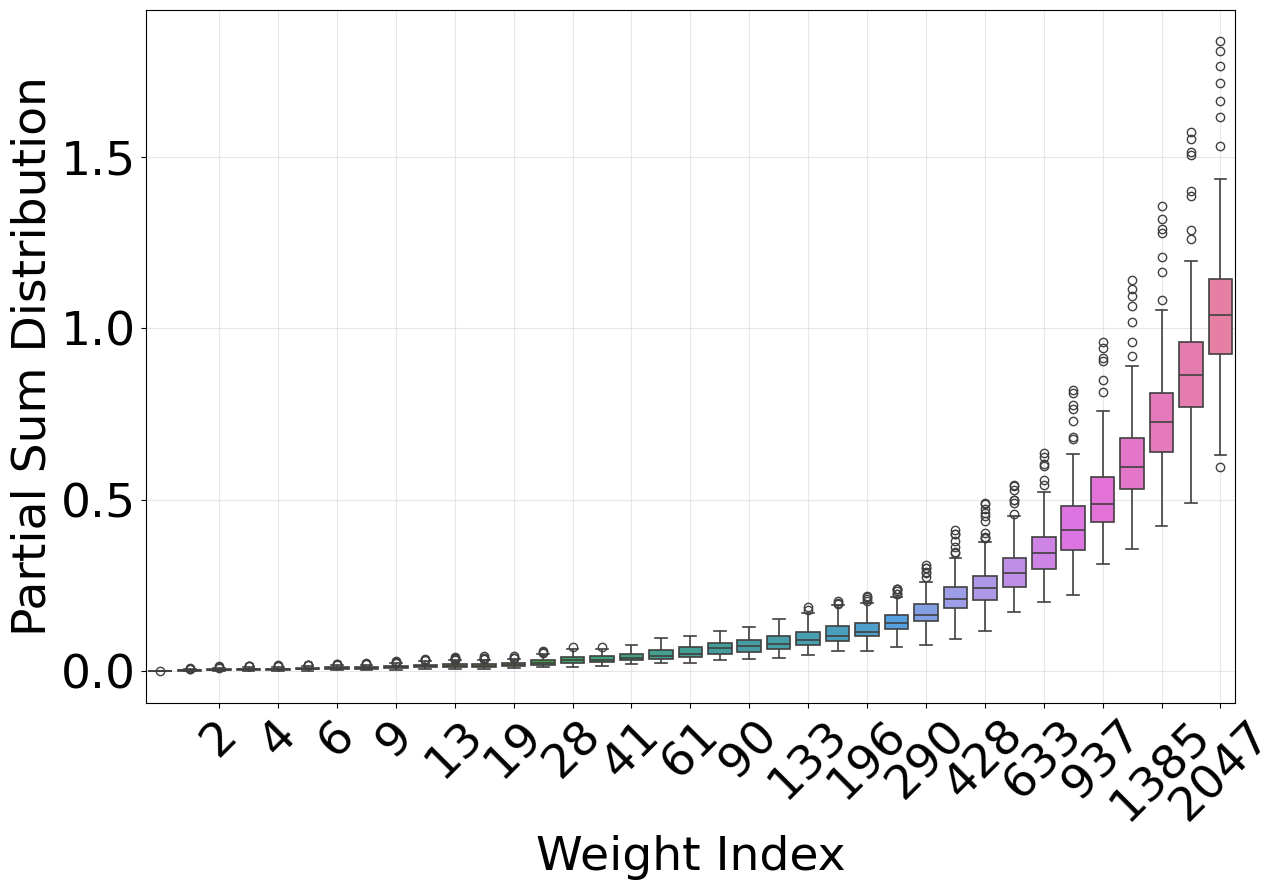

In [ ]:
seaborn_boxplot_symlog_colored((res), num_bins=40, fontsize=34, figsize=(13,9))